# Create a DEG list of the primary vs metastic tumours in the data from NR Atlas using Pseudobulking
## Looking at all the DCs here first

Performing DEG analysis (limma, R) on all cancer data from the NR_atlas all DC data. Using code from NR's 2025-01-13-Pseudo_Cancer_DEGS.ipynb

Date: 09.04.2026

In [1]:
### install packages required

library(Seurat)
library(sceasy)
library(reticulate)
use_condaenv('R_env')
library(limma)
library(edgeR)
library(dplyr)
library(ggplot2)
library(ggrepel)
library(Matrix)
library(tidyr)

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.5; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Loading required package: reticulate


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘tidyr’


The following objects are masked from ‘package:Matrix’:

    expand, pack, unpack




## Read in data(converted seurat object)

In [2]:
#Set working directory
getwd()
setwd("/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/R_Jupyter_Analysis")

[1] "/scratch/user/uqlbukat"

In [3]:
data <- readRDS('/scratch/user/uqlbukat/NRAtlas_analysis_2026/AllDC_bbknndata.RDS')

In [4]:
head(data@meta.data)

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,⋯,Technology,NR_annotations_simple,sample_type_major2,cancer_with_H,cancer_broadest,patient_treatment,DC1_sig,DC2_sig,DC3_sig,mregDC_sig
,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
GSE215120_AM1_AAATGCCCAGAGCCAA-1,17143,2659,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.224990,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1562917,0.28721189,0.462408497,0.36365491
GSE215120_AM1_ACACTGATCCACTGGG-1,18333,2845,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.063656,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1892270,0.26297257,0.329305354,0.54009108
GSE215120_AM1_ACAGCCGCAAACCTAC-1,10581,2182,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.050846,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1352709,0.03988112,0.149324713,0.03211458
GSE215120_AM1_ACCAGTAAGACTGGGT-1,8015,1488,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.033687,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.3672192,-0.12373999,0.004747235,0.27328160
GSE215120_AM1_ACGTCAACAAGGACTG-1,25642,4010,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.835192,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.3290099,-0.25416563,0.017663713,0.11923450
GSE215120_AM1_ACGTCAATCCGCATCT-1,9833,2074,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.311909,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1467211,0.08149318,0.174721746,-0.17654256


In [5]:
table(data$ident)


all_integrated_intersect 
                   29887 

# Start with mreg DC

In [6]:
getwd()

[1] "/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/R_Jupyter_Analysis"

In [7]:
setwd("/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/Pseudobulk")

In [8]:
#load data
sampleinfo <- read.csv("pseudobulk_sampletype_metadata_mregDC.csv", row.names =1)
head(sampleinfo)

,sample_type_major2
,<chr>
GGSE223063_GLIO_1,primary tumour
GSE112271_HCC_Pt13,primary tumour
GSE112271_HCC_Pt14,primary tumour
GSE131907_Healthy_N0001,healthy
GSE131907_Healthy_N0006,healthy
GSE131907_Healthy_N0008,healthy


In [9]:
dim(sampleinfo)

[1] 536   1

In [10]:
cts_mregDC <- read.csv("pseudobulk_mregDC_data.csv", row.names = 1)

In [11]:
head(cts_mregDC)

,GGSE223063_GLIO_1,GSE112271_HCC_Pt13,GSE112271_HCC_Pt14,GSE131907_Healthy_N0001,GSE131907_Healthy_N0006,GSE131907_Healthy_N0008,GSE131907_Healthy_N0009,GSE131907_Healthy_N0018,GSE131907_Healthy_N0019,GSE131907_Healthy_N0020,⋯,PRJCA005422_HGSOC10_AS,PRJCA005422_HGSOC10_PT,PRJNA907381_MEL002_iLN,PRJNA907381_MEL002_uLN,PRJNA907381_MEL009_iLN,PRJNA907381_MEL014_iLN,PRJNA907381_MEL014_uLN,PRJNA907381_MEL018_iLN,PRJNA907381_MEL018_uLN,PRJNA907381_MEL022_iLN
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FAM87B,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
LINC00115,0,0,0,0,0,1,0,1,0,0,⋯,0,0,0,1,0,1,0,0,2,0
FAM41C,0,0,0,0,0,1,0,0,2,0,⋯,0,0,0,4,0,0,0,0,3,0
SAMD11,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
NOC2L,2,0,3,5,1,2,0,6,3,2,⋯,0,0,1,27,1,2,1,4,23,0
KLHL17,0,0,0,0,0,0,0,0,0,0,⋯,1,0,0,6,1,0,0,1,5,0


In [12]:
dim(cts_mregDC)

[1] 15074   536

In [13]:
# set genes variables
genes <- data.frame(Symbol = row.names(cts_mregDC))    

In [14]:
# create DGEList variable
y <- DGEList(counts = cts_mregDC, genes = genes)

In [15]:
head(y, n =2)

An object of class "DGEList"
$counts
          GGSE223063_GLIO_1 GSE112271_HCC_Pt13 GSE112271_HCC_Pt14
FAM87B                    0                  0                  0
LINC00115                 0                  0                  0
          GSE131907_Healthy_N0001 GSE131907_Healthy_N0006
FAM87B                          0                       0
LINC00115                       0                       0
          GSE131907_Healthy_N0008 GSE131907_Healthy_N0009
FAM87B                          0                       0
LINC00115                       1                       0
          GSE131907_Healthy_N0018 GSE131907_Healthy_N0019
FAM87B                          0                       0
LINC00115                       1                       0
          GSE131907_Healthy_N0020 GSE131907_Healthy_N0028
FAM87B                          0                       0
LINC00115                       0                       0
          GSE131907_Healthy_N0030 GSE131907_Healthy_N0031
FAM87B                          0                       0
LINC00115                       0                       0
          GSE131907_Healthy_N0034 GSE131907_LUAD_B3002 GSE131907_LUAD_B3003
FAM87B                          0                    0                    0
LINC00115                       0                    0                    0
          GSE131907_LUAD_B3004 GSE131907_LUAD_B3017 GSE131907_LUAD_B3019
FAM87B                       0                    0                    0
LINC00115                    0                    0                    0
          GSE131907_LUAD_L1010 GSE131907_LUAD_L1011 GSE131907_LUAD_L1012
FAM87B                       1                    0                    0
LINC00115                    0                    0                    0
          GSE131907_LUAD_L1013 GSE131907_LUAD_L1015 GSE131907_LUAD_L1019
FAM87B                       0                    0                    0
LINC00115                    0                    0                    0
          GSE131907_LUAD_L1051 GSE131907_LUAD_T0006 GSE131907_LUAD_T0008
FAM87B                       0                    0                    0
LINC00115                    0                    0                    0
          GSE131907_LUAD_T0009 GSE131907_LUAD_T0018 GSE131907_LUAD_T0019
FAM87B                       0                    0                    0
LINC00115                    0                    0                    0
          GSE131907_LUAD_T0020 GSE131907_LUAD_T0025 GSE131907_LUAD_T0028
FAM87B                       0                    0                    0
LINC00115                    0                    1                    1
          GSE131907_LUAD_T0030 GSE131907_LUAD_T0031 GSE131907_LUAD_T0034
FAM87B                       0                    0                    0
LINC00115                    0                    0                    0
          GSE131907_LUAD_T1028 GSE131907_LUAD_T1058 GSE139324_HNSCC_1
FAM87B                       0                    0                 0
LINC00115                    0                    0                 0
          GSE139324_HNSCC_2 GSE139324_HNSCC_3 GSE139324_HNSCC_4
FAM87B                    0                 0                 0
LINC00115                 1                 1                 1
          GSE139324_HNSCC_5 GSE139324_HNSCC_6 GSE139324_HNSCC_7
FAM87B                    0                 0                 0
LINC00115                 0                 0                 0
          GSE139324_HNSCC_8 GSE139324_HNSCC_9 GSE139324_HNSCC_10
FAM87B                    0                 0                  0
LINC00115                 0                 0                  0
          GSE139324_HNSCC_11 GSE139324_HNSCC_12 GSE139324_HNSCC_13
FAM87B                     0                  0                  0
LINC00115                  0                  0                  1
          GSE139324_HNSCC_14 GSE139324_HNSCC_15 GSE139324_HNSCC_16
FAM87B                     0                  0                  0
LINC00115 

In [16]:
dim(y)

[1] 15074   536

###  Filtering:

In [17]:
# Keep genes with total counts more than 50.
A <- rowSums(y$counts)
isexpr <- A > 50

In [18]:
# Keep only genes with defined annotation:
hasannot <- rowSums(is.na(y$genes)) == 0

In [19]:
y <- y[isexpr & hasannot, , keep.lib.size = FALSE]
dim(y)
     

[1] 10887   536

### Normalise

In [20]:
y <- calcNormFactors(y)

In [21]:
head(y)

An object of class "DGEList"
$counts
          GGSE223063_GLIO_1 GSE112271_HCC_Pt13 GSE112271_HCC_Pt14
LINC00115                 0                  0                  0
FAM41C                    0                  0                  0
NOC2L                     2                  0                  3
KLHL17                    0                  0                  0
HES4                      0                  2                 12
ISG15                     0                  5                 36
          GSE131907_Healthy_N0001 GSE131907_Healthy_N0006
LINC00115                       0                       0
FAM41C                          0                       0
NOC2L                           5                       1
KLHL17                          0                       0
HES4                            1                       0
ISG15                          10                       1
          GSE131907_Healthy_N0008 GSE131907_Healthy_N0009
LINC00115                       1                       0
FAM41C                          1                       0
NOC2L                           2                       0
KLHL17                          0                       0
HES4                            0                       0
ISG15                           9                       0
          GSE131907_Healthy_N0018 GSE131907_Healthy_N0019
LINC00115                       1                       0
FAM41C                          0                       2
NOC2L                           6                       3
KLHL17                          0                       0
HES4                            7                       1
ISG15                           9                       9
          GSE131907_Healthy_N0020 GSE131907_Healthy_N0028
LINC00115                       0                       0
FAM41C                          0                       0
NOC2L                           2                       0
KLHL17                          0                       0
HES4                            0                       1
ISG15                           7                       0
          GSE131907_Healthy_N0030 GSE131907_Healthy_N0031
LINC00115                       0                       0
FAM41C                          0                       0
NOC2L                           1                       0
KLHL17                          0                       0
HES4                            0                       0
ISG15                           0                       2
          GSE131907_Healthy_N0034 GSE131907_LUAD_B3002 GSE131907_LUAD_B3003
LINC00115                       0                    0                    0
FAM41C                          0                    0                    0
NOC2L                           1                    0                    0
KLHL17                          0                    0                    0
HES4                            1                    0                    0
ISG15                           4                    0                    0
          GSE131907_LUAD_B3004 GSE131907_LUAD_B3017 GSE131907_LUAD_B3019
LINC00115                    0                    0                    0
FAM41C                       0                    0                    0
NOC2L                        0                    0                    0
KLHL17                       0                    0                    0
HES4                         0                    0                    1
ISG15                        1                    0                    4
          GSE131907_LUAD_L1010 GSE131907_LUAD_L1011 GSE131907_LUAD_L1012
LINC00115                    0                    0                    0
FAM41C                       0                    0                    0
NOC2L                        1                    0                    3
KLHL17                       0                    0                    0
HES4                         0                    0            

## Multi-dimensional scaling (MDS) plot to visualise relationship between samples

In [22]:
library(RColorBrewer)

In [23]:
unique(data$cancer_broadest)

[1] MEL   BC    HNSCC NSCLC NA    HGSOC PDAC  CRC   GBM   GAC   HCC   iCCA 
[13] NPC  
Levels: BC CRC GAC GBM HCC HGSOC HNSCC MEL NA NPC NSCLC PDAC iCCA

In [24]:
unique(data$NR_annotations_simple)

[1] cDC2   cDC1   mregDC
Levels: cDC1 cDC2 mregDC

In [25]:
unique(data$sample_type_major2)

[1] primary tumour    metastatic tumour healthy           ascites          
Levels: ascites healthy metastatic tumour primary tumour

In [26]:
head(sampleinfo)

,sample_type_major2
,<chr>
GGSE223063_GLIO_1,primary tumour
GSE112271_HCC_Pt13,primary tumour
GSE112271_HCC_Pt14,primary tumour
GSE131907_Healthy_N0001,healthy
GSE131907_Healthy_N0006,healthy
GSE131907_Healthy_N0008,healthy


In [27]:
# create vector of colours for cancer types
sample_types <- unique(sampleinfo$sample_type_major2)
colors <- brewer.pal(n = length(sample_types), name = "Paired")
     

In [28]:
colors

[1] "#A6CEE3" "#1F78B4" "#B2DF8A" "#33A02C"

In [29]:
# set each sample type to a colour
sample_colors <- setNames(colors, sample_types)

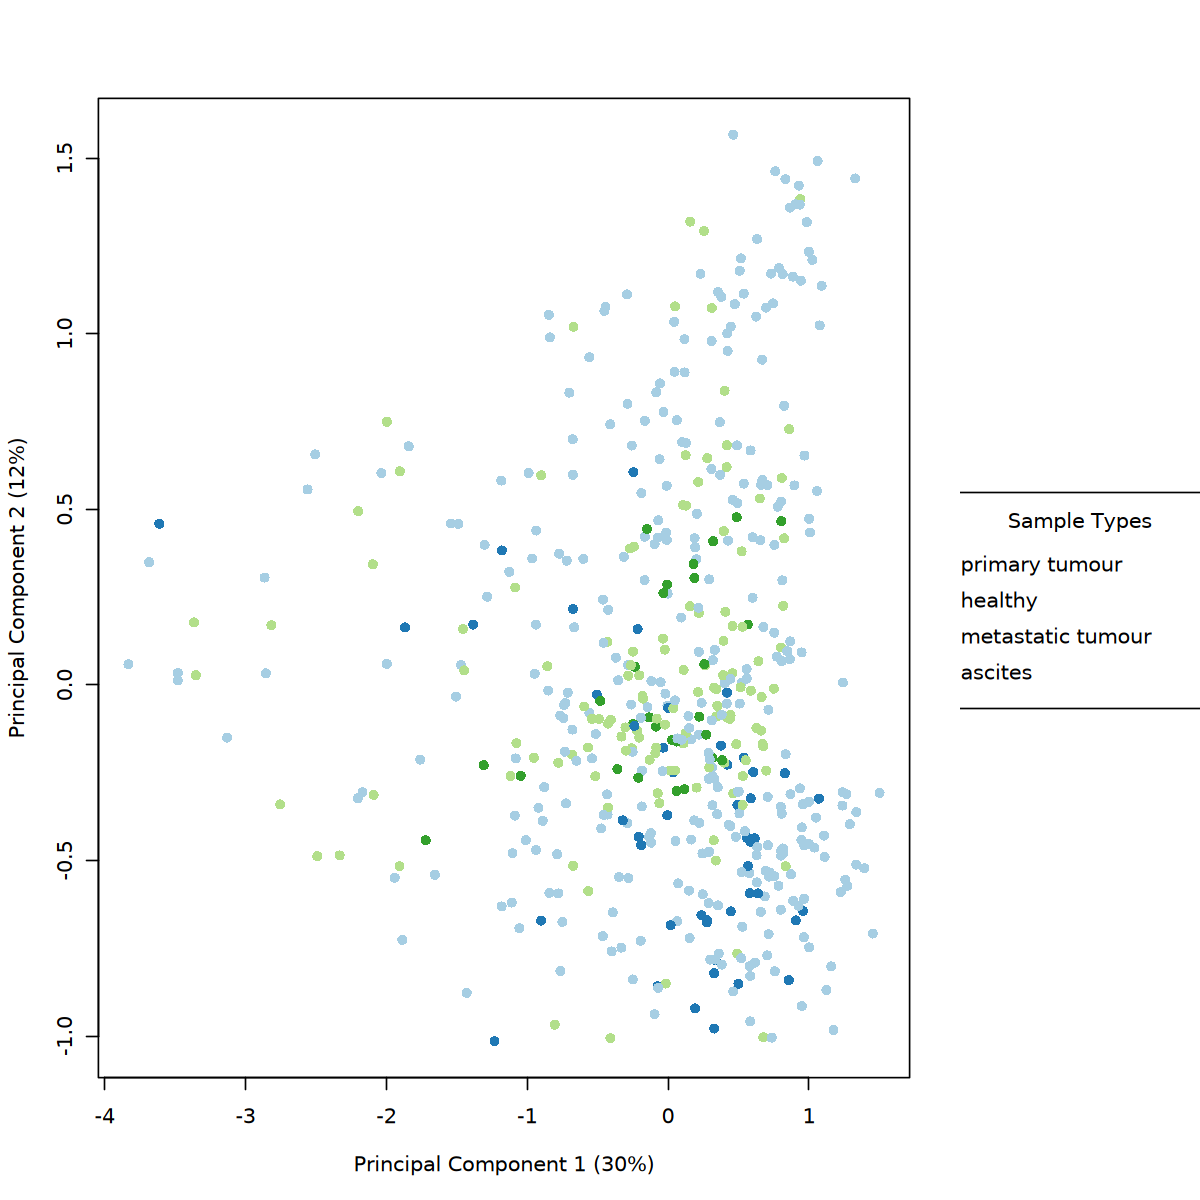

In [30]:
options(repr.plot.height=10, repr.plot.width=10)
layout(matrix(1:2, ncol = 2), widths = c(4, 1))  # Allocate space for the plot and legend

# Generate the MDS plot
plotMDS(y, 
        #labels = sampleinfo$cancer_broadest, 
        labels = NULL,
        col = sample_colors[sampleinfo$sample_type_major2], 
        pch = 16,
        top = 50, 
        gene.selection = "common", 
        prior.count = 5)

# Add a legend
par(mar = c(0, 0, 0, 0))  # Remove margins for the legend area
plot.new()               
legend("center",                        
       legend = sample_types,                 
       col = colors,                        
       pch = 16,                               
       title = "Sample Types")               

# Set Up Model

In [31]:

#setting up the model
design <- model.matrix(~0 + sample_type_major2, data = sampleinfo)

In [32]:
colnames(design) <- c("primary tumour", "metastatic tumour", "healthy", "ascites")

In [40]:
class(design)

[1] "matrix" "array"

In [33]:
head(design)

,primary tumour,metastatic tumour,healthy,ascites
GGSE223063_GLIO_1,0,0,0,1
GSE112271_HCC_Pt13,0,0,0,1
GSE112271_HCC_Pt14,0,0,0,1
GSE131907_Healthy_N0001,0,1,0,0
GSE131907_Healthy_N0006,0,1,0,0
GSE131907_Healthy_N0008,0,1,0,0


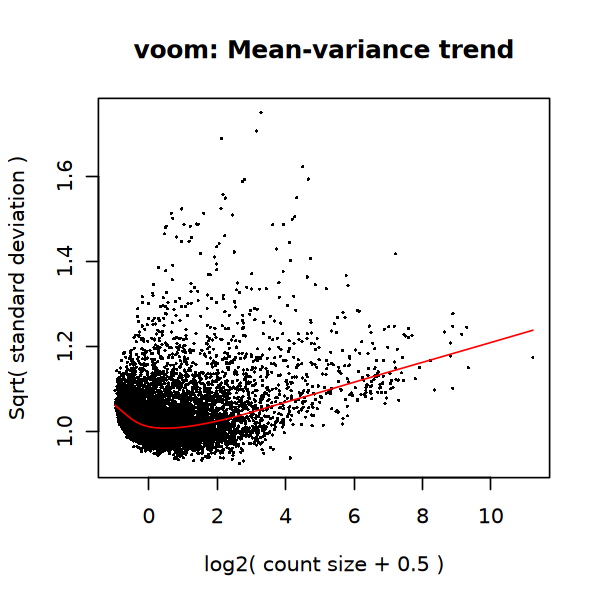

In [34]:
# voom - see here for good v bad voom plot: https://ucdavis-bioinformatics-training.github.io/2018-June-RNA-Seq-Workshop/thursday/DE.html
options(repr.plot.height=5, repr.plot.width=5)
v <- voom(y, design, plot = TRUE)

In [ ]:
# lmFit
fit <- lmFit(v, design)

# Contrast - compare primary to the rest

In [43]:
#duplicate data
design2 <- design
head(design2)


,primary tumour,metastatic tumour,healthy,ascites
GGSE223063_GLIO_1,0,0,0,1
GSE112271_HCC_Pt13,0,0,0,1
GSE112271_HCC_Pt14,0,0,0,1
GSE131907_Healthy_N0001,0,1,0,0
GSE131907_Healthy_N0006,0,1,0,0
GSE131907_Healthy_N0008,0,1,0,0


In [47]:
# Rename columns to remove the spaces
colnames(design2)[1] <- "primary_tumour"
colnames(design2)[2] <- "metastatic_tumour"

In [48]:
head(design2)

,primary_tumour,metastatic_tumour,healthy,ascites
GGSE223063_GLIO_1,0,0,0,1
GSE112271_HCC_Pt13,0,0,0,1
GSE112271_HCC_Pt14,0,0,0,1
GSE131907_Healthy_N0001,0,1,0,0
GSE131907_Healthy_N0006,0,1,0,0
GSE131907_Healthy_N0008,0,1,0,0


In [50]:
# make contrast matrix, apply contrasts, and fit the model 
contrast.matrix <- makeContrasts(primary_tumour - (metastatic_tumour + healthy + ascites), levels=design2) #compare primary to rest
fit2 <- contrasts.fit(fit, contrast.matrix)
fit2 <- eBayes(fit2)

Warning message in contrasts.fit(fit, contrast.matrix):
“row names of contrasts don't match col names of coefficients”


In [51]:
# check the results
tt1 <- topTable(fit2, coef=1, adjust="BH", number = Inf)

In [52]:
# determine which genes significant DEGs
results <- decideTests(fit2)
summary(results)
head(tt1)
     

       primary_tumour - (metastatic_tumour + healthy + ascites)
Down                                                      10887
NotSig                                                        0
Up                                                            0

,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MALAT1,MALAT1,-31.08395,15.84085,-83.68117,0.000000e+00,0.000000e+00,710.8122
MT-CO1,MT-CO1,-26.27397,13.49410,-78.24759,8.637782e-312,4.701977e-308,682.0526
MT-CO2,MT-CO2,-24.94084,12.96490,-75.40613,2.995717e-303,8.153594e-300,665.0853
B2M,B2M,-27.36187,13.94776,-75.56765,9.639208e-304,3.498069e-300,664.5724
RPL13,RPL13,-23.21994,11.92287,-72.63123,1.183581e-294,2.577130e-291,648.2480
H3F3B,H3F3B,-20.08250,10.28171,-70.78234,8.882614e-289,1.611750e-285,638.0956


## Compare primary to each other state

In [53]:
# make contrast matrix, apply contrasts, and fit the model 
contrast.matrix <- makeContrasts(primary_tumour-metastatic_tumour,primary_tumour-healthy,primary_tumour-ascites, levels=design2) #compare primary to every other individually
fit2 <- contrasts.fit(fit, contrast.matrix)
fit2 <- eBayes(fit2)
    

Warning message in contrasts.fit(fit, contrast.matrix):
“row names of contrasts don't match col names of coefficients”


In [54]:
# check the results
tt1 <- topTable(fit2, coef=1, adjust="BH", number = Inf)
tt2 <- topTable(fit2, coef=2, adjust="BH", number = Inf)
tt3 <- topTable(fit2, coef=3, adjust="BH", number = Inf)

In [55]:
# determine which genes significant DEGs
results <- decideTests(fit2)
summary(results)
head(tt1)

       primary_tumour - metastatic_tumour primary_tumour - healthy
Down                                 2147                      793
NotSig                               7808                     9846
Up                                    932                      248
       primary_tumour - ascites
Down                       1150
NotSig                     9142
Up                          595

,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
LMNA,LMNA,-3.925114,6.054923,-9.664439,1.347080e-20,1.466566e-16,35.70627
FOSB,FOSB,-2.982175,7.152590,-8.804221,1.491195e-17,5.508336e-14,29.00254
NR4A2,NR4A2,-3.413435,7.114427,-8.776366,1.856227e-17,5.508336e-14,28.78984
PDE4B,PDE4B,-2.643358,6.416048,-8.765352,2.023821e-17,5.508336e-14,28.72017
FDPS,FDPS,2.252908,6.417271,8.466904,2.041570e-16,4.445315e-13,26.45073
NPFFR1,NPFFR1,2.235585,4.985672,8.337048,5.476734e-16,9.937533e-13,25.54037


In [56]:
# select top 250 up, and 250 down genes from tt1
up_genes_tt1 <- tt1 %>% filter(logFC > 0 & adj.P.Val < 0.05) %>% select(Symbol) %>% head(500) %>% unlist %>% as.character
down_genes_tt1 <- tt1 %>% filter(logFC < 0 & adj.P.Val < 0.05) %>% select(Symbol) %>% head(500) %>% unlist %>% as.character

In [57]:
plot_genes_tt1 <- c(up_genes_tt1, down_genes_tt1)

In [58]:
# log normalise transformed gene expression
mat_tt1 <- v$E[plot_genes_tt1, ]
dim(mat_tt1)

[1] 1000  536

In [59]:
library(pheatmap)

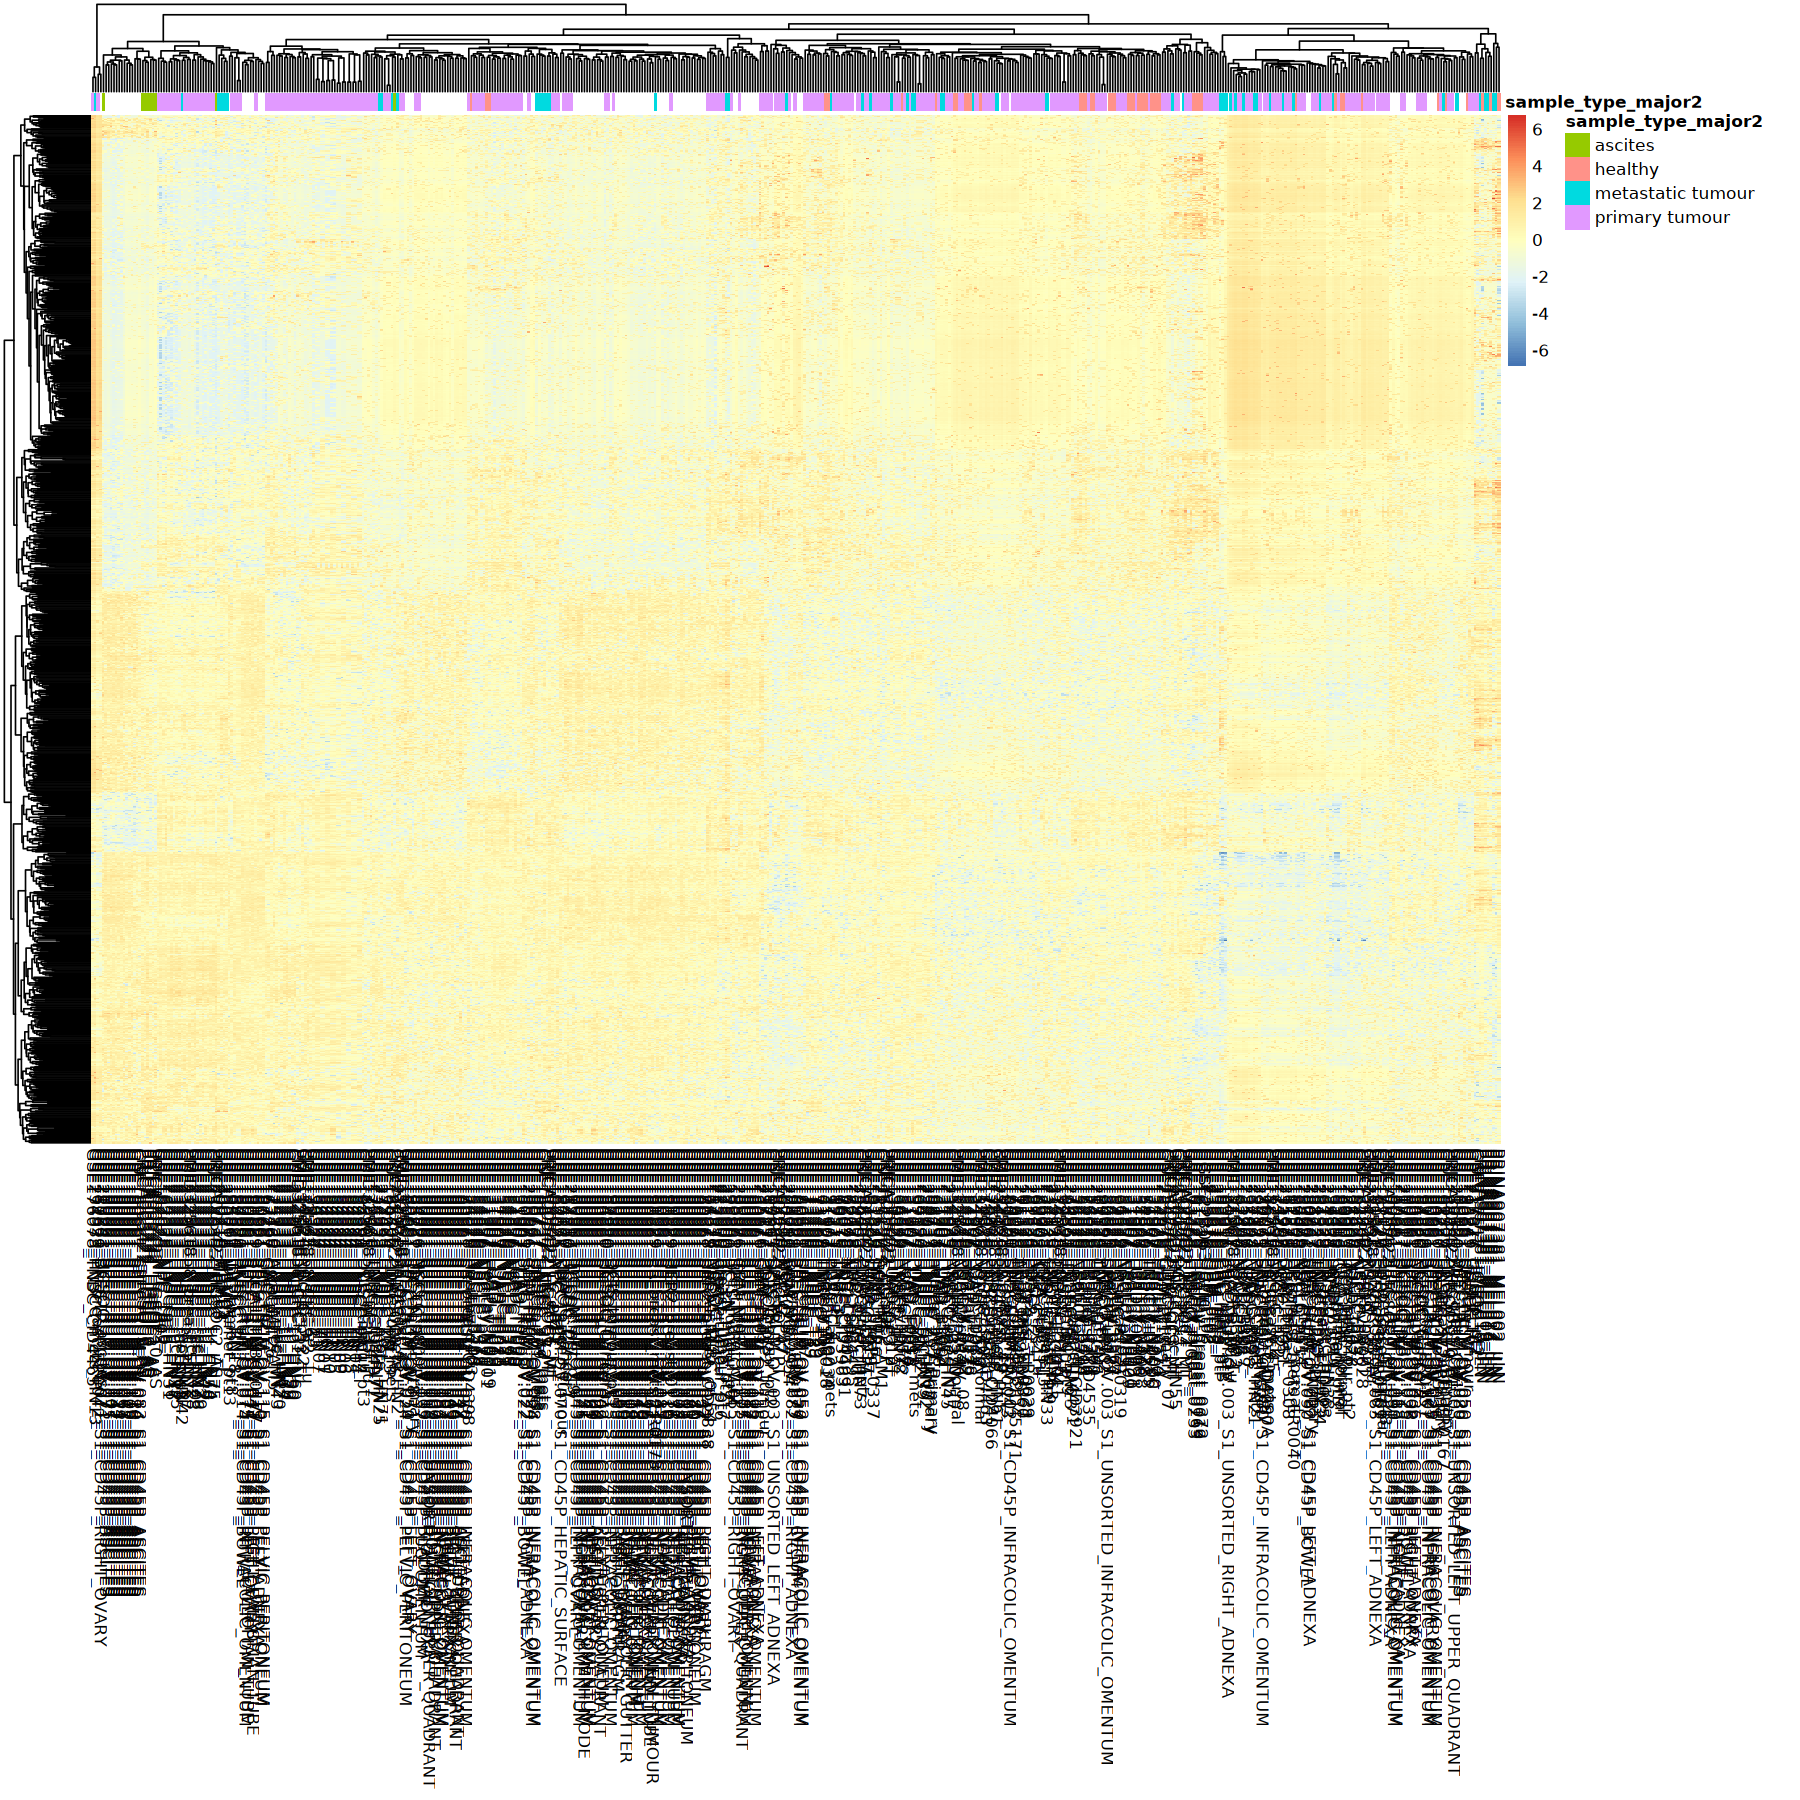

In [60]:
options(repr.plot.height=15, repr.plot.width=15)
pheatmap(mat_tt1, scale = "row", show_rownames = FALSE, annotation_col = sampleinfo[, "sample_type_major2", drop=FALSE])